# Start Here: Your First Machine Learning Model

> **Who is this for?** You can write a little Python and have seen a pandas DataFrame, but you have never trained a machine learning model, or you have copied code without knowing *why* each step is there.
>
> **What you will learn**
> - How to turn a real question into an ML problem: **features** `X`, **target** `y`
> - Why we split data into train and test sets, and what `stratify` does
> - Why every project starts with a **baseline**
> - How to train a model inside a **Pipeline** (`StandardScaler` + `LogisticRegression`) and what `fit`, `predict` and `predict_proba` do
> - How to judge a model: accuracy, the confusion matrix, precision, recall and F1, and why accuracy can lie
> - **Overfitting vs underfitting**, **cross-validation** and choosing a setting with `GridSearchCV`
> - **Data leakage**: a concrete example where a mistake gives a fake score of about 80% on pure noise
> - Saving and loading a model, predicting for a new example
> - A mini regression project with MAE, RMSE and R²
> - A reusable **ML checklist**
>
> **Prerequisites:** Python basics ([`../01_Python/01_basic.ipynb`](../01_Python/01_basic.ipynb)), a first look at pandas and matplotlib ([`../02_Data_Analysis/03_pandas.ipynb`](../02_Data_Analysis/03_pandas.ipynb), [`../02_Data_Analysis/04_matplotlib.ipynb`](../02_Data_Analysis/04_matplotlib.ipynb)). Math is optional; if a symbol puzzles you, see [`../14_Mathematics/00_start_here_math_notation_bridge.ipynb`](../14_Mathematics/00_start_here_math_notation_bridge.ipynb).
>
> **Time needed:** about 1.5 to 2 hours.
>
> **Runs on:** CPU, no API key, no internet. Everything finishes in well under a minute. Data: scikit-learn's built-in breast cancer and diabetes datasets (they ship with the library, nothing is downloaded).

### What is machine learning, in one paragraph?

In normal programming you write the rules: `if size > 3: return "big"`. In **machine learning** you give the computer many **examples** together with the right answers, and an algorithm finds the rules for you. The result is a **model**: a function that takes the facts about a new example and returns a prediction. Learning from examples that come *with* answers is called **supervised learning**, the topic of the next folder, [`01_supervised/`](01_supervised/).

### The road map of this notebook

```
 question -> look at data -> X and y -> train/test split -> baseline -> model (pipeline)
          -> evaluate -> tune with cross-validation (train only) -> ONE final test -> save -> predict
```

---
## 1. Setup

We import the libraries once at the top. **scikit-learn** (imported as `sklearn`) is the standard Python library for classic machine learning: every model in it has the same two main methods, `fit` (learn) and `predict` (answer), which makes it easy to swap one model for another.

In [1]:
import os, shutil, tempfile                      # for saving the model in a throwaway folder
import numpy as np                               # numbers and arrays
import pandas as pd                              # tables (DataFrames)
import matplotlib.pyplot as plt                  # plots
import joblib                                    # saving/loading Python objects (models)

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn import metrics                      # accuracy, precision, recall, ...

SEED = 42                                        # one seed for everything -> same results every run
np.random.seed(SEED)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # plot colours used below
import sklearn; print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.0


**What just happened?** We loaded the tools and fixed a **random seed** (the starting value for the computer's random numbers), so the numbers you see match the ones discussed in this notebook.

---
## 2. The question we are asking

A doctor takes a small tissue sample from a breast lump (a *fine needle aspirate*), and a lab digitises an image of the cells. Software measures the cell nuclei: their radius, texture, smoothness and so on. **Question: from these measurements, can we predict whether the lump is malignant (cancerous) or benign (not cancerous)?**

- The answer is one of two **classes** ("malignant" or "benign"), so this is a **binary classification** problem.
- If the answer were a number (a price, a temperature), it would be a **regression** problem (we do one in Section 13).

> ⚠️ **Important:** this is a teaching dataset from the 1990s (569 patients, Wisconsin, USA). A real medical model needs far more data, clinical validation and regulatory approval. We use it because it is small, clean and the stakes make the evaluation ideas easy to feel.

### 2.1 Look at the data

In [2]:
data = load_breast_cancer(as_frame=True)        # as_frame=True gives pandas objects
df = data.frame.copy()                          # 30 measurement columns + a 'target' column
print("shape (rows, columns):", df.shape)
print("original target names:", [str(t) for t in data.target_names], "-> coded as 0 and 1")
df.iloc[:5, :6]                                 # first 5 rows, first 6 columns (there are 31)

shape (rows, columns): (569, 31)
original target names: ['malignant', 'benign'] -> coded as 0 and 1


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


**What just happened?** We have **569 rows** (one per patient) and **31 columns**: 30 measurements plus `target`. Each row is an **example** (also called a *sample* or *observation*). Each measurement column is a **feature**. We only displayed the first 6 columns to keep it readable.

### 2.2 Make "1" mean the thing we are looking for

In scikit-learn's version of this dataset, `0` = malignant and `1` = benign. That is backwards for us: by convention the **positive class** (coded `1`) is the thing we are trying to *detect* (cancer, fraud, spam). Metrics like precision and recall (Section 7) are computed for the positive class, so we flip the coding now.

In [3]:
df["malignant"] = 1 - df["target"]              # now 1 = malignant (positive), 0 = benign
df = df.drop(columns="target")                  # remove the old, confusing column

counts = df["malignant"].value_counts()         # how many of each class?
print(counts.rename({0: "benign (0)", 1: "malignant (1)"}))
print("fraction malignant:", round(df["malignant"].mean(), 3))

malignant
benign (0)       357
malignant (1)    212
Name: count, dtype: int64
fraction malignant: 0.373


**What just happened?** 212 tumours are malignant and 357 benign, so about **37%** of examples are positive. This **class balance** matters: a model that always says "benign" would already be right about 63% of the time. Keep that number in mind for Section 5.

In [4]:
cols = ["mean radius", "mean texture", "mean concave points", "worst area"]
df[cols].describe().round(2)                    # count, mean, std, min, quartiles, max

,mean radius,mean texture,mean concave points,worst area
count,569.00,569.00,569.00,569.00
mean,14.13,19.29,0.05,880.58
std,3.52,4.30,0.04,569.36
min,6.98,9.71,0.00,185.20
25%,11.70,16.17,0.02,515.30
50%,13.37,18.84,0.03,686.50
75%,15.78,21.80,0.07,1084.00
max,28.11,39.28,0.20,4254.00


**What just happened?** `describe()` gives a quick numerical summary of each column. Two things to notice: there are **no missing values** (every `count` is 569), and the columns live on **very different scales**: `mean concave points` is below 0.21 while `worst area` goes up to 4254. Many models are sensitive to scale; we deal with it in Section 6 with `StandardScaler`.

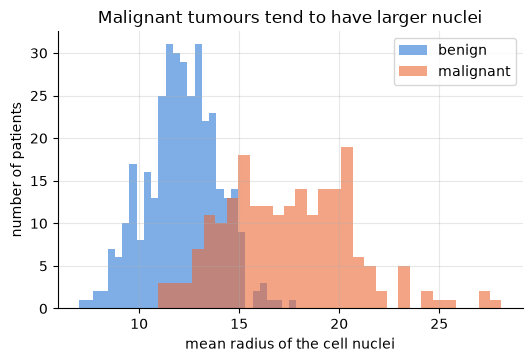

In [5]:
fig, ax = plt.subplots()
for label, colour, name in [(0, BLUE, "benign"), (1, ORANGE, "malignant")]:
    ax.hist(df.loc[df["malignant"] == label, "mean radius"], bins=30, alpha=0.6,
            color=colour, label=name)            # one histogram per class
ax.set_xlabel("mean radius of the cell nuclei"); ax.set_ylabel("number of patients")
ax.set_title("Malignant tumours tend to have larger nuclei"); ax.legend(); plt.show()

**What just happened?** Malignant tumours (orange) mostly have larger cell nuclei than benign ones (blue), but the two histograms **overlap** between roughly 11 and 17. One feature alone cannot separate the classes perfectly; a model combines all 30 features to do better. A plot like this is a quick sanity check that the features contain *some* signal.

---
## 3. Features `X` and target `y`

| Name | What it is | Shape here |
|---|---|---|
| `X` (capital: it is a table) | the **features**: what the model may look at | 569 rows $\times$ 30 columns |
| `y` (lowercase: it is one column) | the **target** (or *label*): the answer we want to predict | 569 values |

> ⚠️ **Common mistake:** leaving the target inside `X`. The model would simply "read the answer" and look perfect in testing, then fail in real use. Always `drop` the target column from `X`.

In [6]:
X = df.drop(columns="malignant")                # everything except the answer
y = df["malignant"]                             # only the answer
print("X shape:", X.shape, "  y shape:", y.shape)
print("is the target accidentally inside X?", "malignant" in X.columns)

X shape: (569, 30)   y shape: (569,)
is the target accidentally inside X? False


**What just happened?** `X` has 30 feature columns, `y` has one value per patient, and we double-checked that the answer is not hiding inside `X`.

---
## 4. Train/test split: don't grade the exam with the questions you studied

Imagine a student who gets the exact exam questions (with answers) the night before. They score 100%, but have they learned anything? We can't tell. The same is true for a model: scoring it on the data it learned from tells us nothing about how it does on **new** patients.

So we hide part of the data away:
- **Training set**: the model learns from it (the "study material").
- **Test set**: used **once**, at the very end, to estimate performance on unseen data (the "real exam").

```
 all 569 patients
 ├── 75% training set  -> learn, compare models, tune settings
 └── 25% test set      -> locked in a drawer until the very end
```

**`stratify=y`** makes both parts keep the same malignant/benign ratio as the full data. Without it, by bad luck the test set could get, say, very few malignant cases. **`random_state`** fixes the shuffle so the split is repeatable.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,          # 25% for the test set
    stratify=y,              # keep the class ratio the same in both parts
    random_state=SEED,       # repeatable shuffle
)
print("train:", X_train.shape, "  test:", X_test.shape)
print("fraction malignant  all: %.3f  train: %.3f  test: %.3f"
      % (y.mean(), y_train.mean(), y_test.mean()))

train: (426, 30)   test: (143, 30)
fraction malignant  all: 0.373  train: 0.373  test: 0.371


**What just happened?** 426 patients for training, 143 for testing, and thanks to `stratify` all three groups have about 37% malignant cases. From now on, **everything we learn or decide uses only the training set**. The test set is touched exactly once, in Section 10.

---
## 5. Start with a baseline

A **baseline** is the score of the dumbest reasonable strategy. Here: "always predict the most common class" (benign). It answers the question *"is my model actually learning anything?"*. If a fancy model can't beat the baseline, something is wrong (a bug, useless features, or a problem that can't be solved with this data).

scikit-learn has ready-made baselines: `DummyClassifier` and `DummyRegressor`.

In [8]:
baseline = DummyClassifier(strategy="most_frequent")   # always predicts the most common class
baseline.fit(X_train, y_train)                         # "learns" which class is most common
base_pred = baseline.predict(X_test)                   # predicts 0 (benign) for everybody

print("baseline predictions (first 10):", base_pred[:10])
print("baseline accuracy :", round(metrics.accuracy_score(y_test, base_pred), 3))
print("malignant tumours it caught:", int(((base_pred == 1) & (y_test == 1)).sum()), "of", int(y_test.sum()))

baseline predictions (first 10): [0 0 0 0 0 0 0 0 0 0]
baseline accuracy : 0.629
malignant tumours it caught: 0 of 53


**What just happened?** The baseline says "benign" for everybody and is still **about 63% accurate**, simply because 63% of the test tumours are benign. But it catches **zero** of the 53 malignant tumours, which makes it useless as a medical tool. Remember: **63% accuracy is the bar to beat**, and accuracy alone hides the most important failure.

---
## 6. Train a real model: a Pipeline of `StandardScaler` + `LogisticRegression`

**`LogisticRegression`** (despite its name, a *classification* model) computes a weighted sum of the features, one weight per feature, and squashes it into a probability between 0 and 1 with the sigmoid function. Training = finding the weights that best separate the two classes. (The math is in [`01_supervised/02_logistic_regression.ipynb`](01_supervised/02_logistic_regression.ipynb).)

**`StandardScaler`** rescales each feature to have mean 0 and standard deviation 1. Without it, `worst area` (values in the thousands) would dominate features measured in fractions, and the training algorithm converges more slowly.

**`Pipeline`** glues the steps into a single model object:
```
 raw features --> [StandardScaler] --> [LogisticRegression] --> prediction
```
Calling `pipe.fit(X_train, y_train)` fits the scaler on the training data and then the model on the scaled data. Calling `pipe.predict(X_new)` applies the **same** scaling (learned from training data) before predicting. That "same scaling" is what protects you from **data leakage** (Section 11).

| Method | What it does | Returns |
|---|---|---|
| `fit(X, y)` | learn from examples **with** answers | the fitted model |
| `predict(X)` | give a hard answer for each row | `0` or `1` per row |
| `predict_proba(X)` | give a probability for each class | two columns: P(class 0), P(class 1) |

In [9]:
pipe = Pipeline([
    ("scale", StandardScaler()),                      # step 1: put features on the same scale
    ("model", LogisticRegression(max_iter=1000)),     # step 2: the classifier
])
pipe.fit(X_train, y_train)                            # learn from the TRAINING set only

y_pred = pipe.predict(X_test)                         # hard answers: 0 or 1
y_proba = pipe.predict_proba(X_test)[:, 1]            # probability of class 1 (malignant)

preview = pd.DataFrame({"true": y_test.values[:8], "predicted": y_pred[:8],
                        "P(malignant)": y_proba[:8].round(3)})
preview

,true,predicted,P(malignant)
0,1,1,0.999
1,0,0,0.004
2,1,1,1.000
3,0,0,0.000
4,0,0,0.035
5,0,0,0.004
6,0,0,0.000
7,0,0,0.002


**What just happened?** `fit` trained the pipeline on 426 patients. For each test patient, `predict_proba` gives the model's probability of malignancy, and `predict` turns it into a hard answer using a **threshold of 0.5**: probability above 0.5 means "malignant" (1). Most probabilities are very close to 0 or 1 (the model is confident), and a few sit in between, which are the hard cases.

> 💡 **Tip:** `predict_proba(X)` returns **two** columns, one per class, in the order of `pipe.classes_` (here `[0, 1]`). `[:, 1]` selects the second column: the probability of the positive class.

---
## 7. Evaluate: accuracy, confusion matrix, precision, recall, F1

### 7.1 Accuracy and the confusion matrix

**Accuracy** = fraction of predictions that are correct. Simple, but it treats every mistake as equally bad. In medicine, the two kinds of mistakes are very different:

|  | **predicted benign (0)** | **predicted malignant (1)** |
|---|---|---|
| **actually benign (0)** | **TN** true negative: correctly reassured | **FP** false positive: a false alarm, an unnecessary biopsy and worry |
| **actually malignant (1)** | **FN** false negative: **a missed cancer** | **TP** true positive: cancer correctly caught |

This 2 $\times$ 2 table of counts is the **confusion matrix**.

model accuracy   : 0.965   (baseline was 0.629 )
TN=89  FP=1  FN=4  TP=49


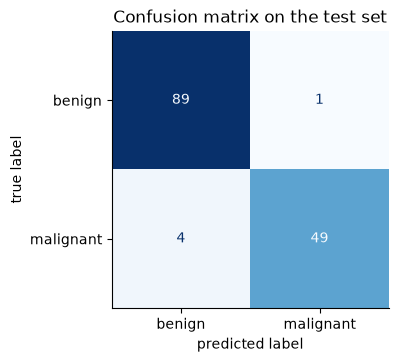

In [10]:
acc = metrics.accuracy_score(y_test, y_pred)
print("model accuracy   :", round(acc, 3), "  (baseline was", round(metrics.accuracy_score(y_test, base_pred), 3), ")")

cm = metrics.confusion_matrix(y_test, y_pred)          # rows = truth, columns = prediction
tn, fp, fn, tp = cm.ravel()                             # unpack the four counts
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

disp = metrics.ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
disp.plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix on the test set"); plt.grid(False)
plt.xlabel("predicted label"); plt.ylabel("true label"); plt.show()

**What just happened?** The model is far better than the baseline (about 96.5% vs 62.9% accuracy). The confusion matrix shows *where* the mistakes are: the diagonal (top-left TN = 89, bottom-right TP = 49) holds the 138 correct answers, and the off-diagonal cells hold **1 false alarm** (FP, top-right) and **4 missed cancers** (FN, bottom-left). Accuracy alone would never have told you that most of the errors are the dangerous kind.

### 7.2 Precision, recall and F1 in plain English

| Metric | Question it answers (positive = malignant) | Formula |
|---|---|---|
| **Precision** | "When the model says *cancer*, how often is it right?" (few false alarms) | $\dfrac{TP}{TP + FP}$ |
| **Recall** (also *sensitivity*) | "Of all real cancers, how many did the model catch?" (few missed cancers) | $\dfrac{TP}{TP + FN}$ |
| **F1 score** | one number that is high only if **both** are high | $2 \cdot \dfrac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$ |

For cancer screening, **recall** usually matters most: a missed cancer (FN) is far worse than a false alarm (FP). For a spam filter it's the opposite: a real email thrown into spam (FP) is worse, so **precision** matters more. *Which mistake is more expensive?* is a business or medical question, not a math one.

In [11]:
precision_hand = tp / (tp + fp)
recall_hand = tp / (tp + fn)
f1_hand = 2 * precision_hand * recall_hand / (precision_hand + recall_hand)
print(f"by hand : precision={precision_hand:.3f}  recall={recall_hand:.3f}  F1={f1_hand:.3f}")
print(f"sklearn : precision={metrics.precision_score(y_test, y_pred):.3f}  "
      f"recall={metrics.recall_score(y_test, y_pred):.3f}  F1={metrics.f1_score(y_test, y_pred):.3f}")
print()
print(metrics.classification_report(y_test, y_pred, target_names=["benign", "malignant"], digits=3))

by hand : precision=0.980  recall=0.925  F1=0.951
sklearn : precision=0.980  recall=0.925  F1=0.951

              precision    recall  f1-score   support

      benign      0.957     0.989     0.973        90
   malignant      0.980     0.925     0.951        53

    accuracy                          0.965       143
   macro avg      0.968     0.957     0.962       143
weighted avg      0.966     0.965     0.965       143



**What just happened?** Our hand calculations from the confusion matrix match scikit-learn: precision $= 49 / (49 + 1) = 0.980$ (when it says cancer, it is almost always right) and recall $= 49 / (49 + 4) = 0.925$ (it catches about 92 of every 100 cancers). `classification_report` prints precision, recall and F1 for **each** class, plus **support** (how many test examples truly belong to that class: 90 benign, 53 malignant). Look at the *malignant* row: that's the one a doctor cares about.

### 7.3 Moving the threshold trades precision for recall

`predict` uses a 0.5 threshold. If missed cancers are much worse than false alarms, we can flag a tumour as malignant at a **lower** probability, for example 0.3. We catch more cancers (higher recall) at the price of more false alarms (lower precision).

In [12]:
for threshold in [0.5, 0.3, 0.1]:
    pred_t = (y_proba >= threshold).astype(int)            # our own threshold instead of 0.5
    tn_t, fp_t, fn_t, tp_t = metrics.confusion_matrix(y_test, pred_t).ravel()
    print(f"threshold {threshold}: missed cancers (FN) = {fn_t}, false alarms (FP) = {fp_t}, "
          f"recall = {tp_t/(tp_t+fn_t):.3f}, precision = {tp_t/(tp_t+fp_t):.3f}")

threshold 0.5: missed cancers (FN) = 4, false alarms (FP) = 1, recall = 0.925, precision = 0.980
threshold 0.3: missed cancers (FN) = 2, false alarms (FP) = 1, recall = 0.962, precision = 0.981
threshold 0.1: missed cancers (FN) = 1, false alarms (FP) = 6, recall = 0.981, precision = 0.897


**What just happened?** Lowering the threshold from 0.5 to 0.3 cut the missed cancers from 4 to 2 with no extra false alarms; going down to 0.1 cut them to 1, but false alarms jumped from 1 to 6. In general, a lower threshold never increases missed cancers and tends to add false alarms. There is no free lunch: you choose the threshold based on the cost of each mistake. (Strictly, the threshold should also be chosen on training/validation data, not the test set; here we only *look* at the trade-off.)

### 7.4 Why accuracy can mislead on imbalanced data

Our dataset is only mildly imbalanced (37% / 63%). Many real problems are extreme: fraud, rare diseases, machine failures. Imagine 1,000 patients of whom only 10 are sick, and a "model" that always says "healthy".

In [13]:
y_true_rare = np.array([1] * 10 + [0] * 990)       # 10 sick, 990 healthy
y_pred_lazy = np.zeros(1000, dtype=int)            # a lazy model: "everyone is healthy"

print("accuracy :", metrics.accuracy_score(y_true_rare, y_pred_lazy))
print("recall   :", metrics.recall_score(y_true_rare, y_pred_lazy))
print("precision:", metrics.precision_score(y_true_rare, y_pred_lazy, zero_division=0))

accuracy : 0.99
recall   : 0.0
precision: 0.0


**What just happened?** **99% accuracy** while catching **none** of the sick patients (recall 0). Precision is undefined here (the model never says "sick", so $TP + FP = 0$); `zero_division=0` tells scikit-learn to report 0 instead of printing a warning. Lesson: **on imbalanced data, always look at the confusion matrix and at recall/precision, never at accuracy alone.** [`05_feature_engineering/02_imbalanced_data.ipynb`](05_feature_engineering/02_imbalanced_data.ipynb) covers how to handle such data.

---
## 8. Overfitting vs underfitting

- **Underfitting**: the model is too simple to capture the pattern. It does badly on training data **and** new data. (A student who didn't study.)
- **Overfitting**: the model is so flexible it memorises the training examples, including their noise. It does great on training data but worse on new data. (A student who memorised last year's answers without understanding.)
- The sweet spot is in between.

A **decision tree** asks a series of yes/no questions ("is worst area > 880?"). Its `max_depth` (the maximum number of questions in a row) controls how flexible it is: depth 1 is a single question; unlimited depth can memorise every training example.

To choose the depth fairly we must **not** use the test set. We carve a **validation set** out of the *training* data:
```
 training set (426)
 ├── sub-train (75%)   -> fit trees of each depth
 └── validation (25%)  -> compare depths
 test set (143)        -> still locked away
```

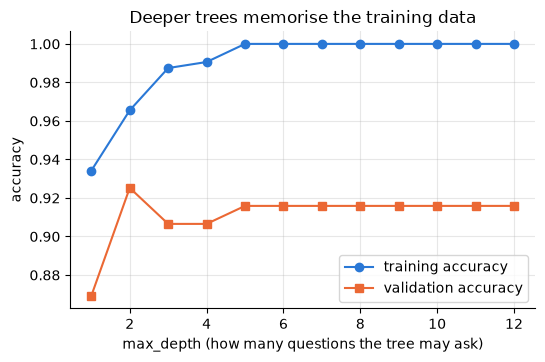

depth  1: train 0.934   validation 0.869   gap +0.065
depth  3: train 0.987   validation 0.907   gap +0.081
depth  5: train 1.000   validation 0.916   gap +0.084
depth  8: train 1.000   validation 0.916   gap +0.084
depth 12: train 1.000   validation 0.916   gap +0.084
depth with the best validation accuracy: 2


In [14]:
X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                              stratify=y_train, random_state=SEED)
depths = range(1, 13)
train_scores, val_scores = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_sub, y_sub)
    train_scores.append(tree.score(X_sub, y_sub))     # .score = accuracy for classifiers
    val_scores.append(tree.score(X_val, y_val))

plt.plot(list(depths), train_scores, "o-", color=BLUE, label="training accuracy")
plt.plot(list(depths), val_scores, "s-", color=ORANGE, label="validation accuracy")
plt.xlabel("max_depth (how many questions the tree may ask)"); plt.ylabel("accuracy")
plt.title("Deeper trees memorise the training data"); plt.legend(); plt.show()
for d, tr, va in zip(depths, train_scores, val_scores):
    if d in (1, 3, 5, 8, 12):
        print(f"depth {d:>2}: train {tr:.3f}   validation {va:.3f}   gap {tr - va:+.3f}")
best_depth = list(depths)[int(np.argmax(val_scores))]
print("depth with the best validation accuracy:", best_depth)

**What just happened?** Training accuracy (blue) climbs steadily and reaches 1.000 (perfect memorisation) from depth 5 on. Validation accuracy (orange) peaks early (depth 2, about 0.925) and never gets better after that, even though the tree keeps getting better at the training data. That **gap** between the two lines (about 0.08 for deep trees) is the signature of **overfitting**: extra depth is spent memorising, not learning. Depth 1 is **underfit**: both scores are at their lowest. The validation curve is bumpy because 107 validation patients is not many (one patient = about 0.9 percentage points); that bumpiness is exactly why we use cross-validation next.

---
## 9. Cross-validation and choosing a hyperparameter

### 9.1 Cross-validation: many small exams instead of one

A single validation split is noisy: a few lucky or unlucky patients change the score. **k-fold cross-validation** splits the training data into $k$ parts (**folds**), trains $k$ times, each time holding out a different fold for scoring, and averages the $k$ scores:

```
 fold:     1      2      3      4      5
 round 1: [val] [trn] [trn] [trn] [trn]
 round 2: [trn] [val] [trn] [trn] [trn]
 ...
 round 5: [trn] [trn] [trn] [trn] [val]
 -> 5 scores -> report mean ± standard deviation
```

`StratifiedKFold` keeps the class ratio the same in every fold. Note that we pass the whole **pipeline**, so the scaler is re-fitted inside every round on that round's training folds only.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # 5 stratified folds
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
print("5 fold scores:", scores.round(3))
print(f"mean accuracy: {scores.mean():.3f} ± {scores.std():.3f}")

5 fold scores: [0.988 0.976 0.953 0.953 0.988]
mean accuracy: 0.972 ± 0.016


**What just happened?** Five scores, one per fold, all high (roughly 0.95 to 1.0). The mean is our best estimate of performance on new data **without touching the test set**, and the ± standard deviation tells us how much it wobbles from split to split.

### 9.2 Choosing a hyperparameter with `GridSearchCV`

A **parameter** is learned from data (the weights). A **hyperparameter** is a setting *you* choose before training: the tree's `max_depth`, or for logistic regression `C`, which controls how strongly weights are kept small (**regularisation**): small `C` = simpler, more restrained model; large `C` = more flexible model.

`GridSearchCV` tries every value in a grid, runs cross-validation for each **on the training set only**, and keeps the best. Inside a pipeline, a step's setting is named `<step name>__<setting>` (two underscores), so `C` of the step called `"model"` is `model__C`.

We score with **F1** (Section 7.2) rather than accuracy because we care about doing well on the malignant class specifically.

In [16]:
param_grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}   # values to try
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1")
search.fit(X_train, y_train)                                  # TRAIN ONLY

results = pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
print(results.round(3).to_string(index=False))
print("best C:", search.best_params_["model__C"], "  best mean CV F1:", round(search.best_score_, 3))

 param_model__C  mean_test_score  std_test_score
          0.001            0.800           0.083
          0.010            0.925           0.031
          0.100            0.954           0.013
          1.000            0.961           0.022
         10.000            0.949           0.024
        100.000            0.946           0.020
best C: 1   best mean CV F1: 0.961


**What just happened?** Each row is one value of `C` with its mean and standard deviation of F1 over the 5 folds. (In `cv_results_` the column is called `mean_test_score`, but here "test" means the held-out fold inside the training set, *not* our real test set.) Very small `C` restrains the model too much (underfitting) and scores lowest; the best value sits in the middle of the grid. Here the winner is `C = 1`, which happens to be scikit-learn's default (so the final model equals the one from Section 6; a search is still how you *know* the default is a good choice). `GridSearchCV` then automatically re-trains the best pipeline on the **whole** training set, available as `search.best_estimator_`.

---
## 10. The one and only final test

Now, and only now, we open the drawer and evaluate the chosen model on the test set **once**. If we went back and tweaked the model after seeing this number, the test set would become just another validation set and our estimate would be optimistic again.

In [17]:
final_model = search.best_estimator_                   # best pipeline, re-fitted on all training data
final_pred = final_model.predict(X_test)

print("test accuracy :", round(metrics.accuracy_score(y_test, final_pred), 3))
print("test precision:", round(metrics.precision_score(y_test, final_pred), 3))
print("test recall   :", round(metrics.recall_score(y_test, final_pred), 3))
print("test F1       :", round(metrics.f1_score(y_test, final_pred), 3))
print("confusion matrix [[TN, FP], [FN, TP]]:", metrics.confusion_matrix(y_test, final_pred).tolist())

test accuracy : 0.965
test precision: 0.98
test recall   : 0.925
test F1       : 0.951
confusion matrix [[TN, FP], [FN, TP]]: [[89, 1], [4, 49]]


**What just happened?** These are the numbers you would report: they come from data the model and all our decisions never saw. Test F1 (0.951) is close to the cross-validation estimate from Section 9 (0.961), which is what we hope to see; a test score much lower than the CV estimate would hint at a problem such as leakage or an unusual split. In plain words: on new patients we expect roughly 96 to 97% accuracy, with about 1 in 13 cancers missed at the default threshold.

---
## 11. Data leakage: how to fool yourself with pure noise

**Data leakage** means information from the data you evaluate on sneaks into training. The model then looks great in your notebook and fails in the real world.

The most common way it happens: doing a data-dependent step (scaling, filling missing values, **choosing features**) on the **full** dataset *before* splitting. Then the "unseen" test rows have already influenced the preprocessing.

### The experiment
- 200 "patients" with 5,000 features of **pure random noise**, and labels assigned by **coin flip**. There is *nothing* to learn: any honest method should score about 50%.
- **Leaky way:** pick the 20 features most correlated with the labels using **all 200 rows**, then cross-validate a model on those 20 features.
- **Correct way:** put the feature selection **inside a pipeline**, so in each CV round it only sees that round's training folds.

In [18]:
def leakage_experiment(seed, k=20):
    rng = np.random.default_rng(seed)
    X_noise = rng.normal(size=(200, 5000))         # 200 rows, 5000 columns of random numbers
    y_noise = rng.integers(0, 2, size=200)         # coin-flip labels: no real pattern exists
    cv_noise = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

    # LEAKY: select features using ALL rows (including the rows we will later "test" on)
    X_selected = SelectKBest(f_classif, k=k).fit_transform(X_noise, y_noise)
    leaky = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cv_noise)

    # CORRECT: selection is a pipeline step, re-done inside every CV round on training folds only
    honest_pipe = Pipeline([("select", SelectKBest(f_classif, k=k)),
                            ("model", LogisticRegression(max_iter=1000))])
    honest = cross_val_score(honest_pipe, X_noise, y_noise, cv=cv_noise)
    return leaky.mean(), honest.mean()

rows = [leakage_experiment(seed) for seed in range(5)]     # 5 different random noise datasets
leak_table = pd.DataFrame(rows, columns=["leaky", "correct"]).rename_axis("noise dataset")
print(leak_table.round(3))
print("average  leaky: %.3f   correct: %.3f   (coin flip = 0.5)" % tuple(leak_table.mean()))

               leaky  correct
noise dataset                
0              0.795    0.550
1              0.765    0.485
2              0.820    0.445
3              0.755    0.525
4              0.805    0.530
average  leaky: 0.788   correct: 0.507   (coin flip = 0.5)


**What just happened?** We repeated the experiment on **5 different random datasets**, because with only 200 rows a single run is noisy (an honest score can land anywhere from about 0.45 to 0.55 by pure luck). The pattern is the same every time: the leaky workflow reports around **0.79** accuracy, the correct one around **0.51**, i.e. a coin flip, which is the truth.

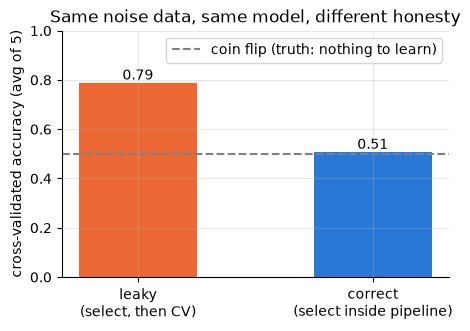

In [19]:
plt.figure(figsize=(5, 3.2))
bars = plt.bar(["leaky\n(select, then CV)", "correct\n(select inside pipeline)"],
               leak_table.mean(), color=[ORANGE, BLUE], width=0.5)
plt.axhline(0.5, ls="--", color="gray", label="coin flip (truth: nothing to learn)")
plt.bar_label(bars, fmt="%.2f")                       # print the value on each bar
plt.ylim(0, 1); plt.ylabel("cross-validated accuracy (avg of 5)")
plt.title("Same noise data, same model, different honesty"); plt.legend(loc="upper right"); plt.show()

**What just happened?** On data that contains **no information at all**, the leaky workflow claims to be right about 4 times out of 5. Why? With 5,000 random features, some will *by chance* line up with the 200 coin-flip labels. Selecting them while looking at **all** the labels, including the labels of the rows later used for scoring, bakes those chance patterns into the "test" folds. The pipeline version picks features using training folds only, so the chance patterns don't carry over to the held-out fold, and the score falls back to about 0.5.

**The same rule applies to scaling, filling missing values, encoding categories and so on.** Scaling on the full data usually leaks only a little (the mean and standard deviation of 569 rows barely change when you drop 143), so the damage is often invisible, which is exactly why it is a bad habit: the day you do something more data-hungry, like feature selection, it bites hard.

> ⚠️ **Common mistake:** `X_scaled = StandardScaler().fit_transform(X)` followed by `train_test_split(X_scaled, ...)`. **Fix:** split first, then put every preprocessing step inside a `Pipeline`, and only ever call `fit` on training data. [`01_supervised/09_pipeline_and_leakage.ipynb`](01_supervised/09_pipeline_and_leakage.ipynb) goes deeper.

---
## 12. Save the model, load it back, predict for a new patient

A trained model is a Python object. **joblib** writes it to a file so another program (an API, a nightly batch job) can load it without re-training. Because we saved the whole **pipeline**, the scaling travels with the model: the new program can't forget it.

We save into a temporary folder that we delete at the end, so this notebook leaves no files behind.

In [20]:
tmp_dir = tempfile.mkdtemp()                          # a throwaway folder
model_path = os.path.join(tmp_dir, "breast_cancer_model.joblib")
joblib.dump(final_model, model_path)                  # save to disk
print("saved file size:", round(os.path.getsize(model_path) / 1024, 1), "KB")

loaded = joblib.load(model_path)                      # load it back (e.g. in another program)
same = (loaded.predict(X_test) == final_model.predict(X_test)).all()
print("loaded model gives identical predictions:", same)

saved file size: 3.0 KB
loaded model gives identical predictions: True


**What just happened?** The whole pipeline (scaler + logistic regression) fits in a small file, and the loaded copy predicts exactly like the original.

> ⚠️ **Common mistake:** only load `.joblib` / pickle files **you trust**. Loading one can run arbitrary code. Also load it with the same scikit-learn version you saved it with; other versions may warn or behave differently.

In [21]:
# A "new patient": in real life these 30 numbers come from the lab. Here we reuse one test row.
new_patient = X_test.iloc[[0]]                           # double brackets keep it a 1-row DataFrame
p = loaded.predict_proba(new_patient)[0, 1]              # probability of malignant
print(f"P(malignant) = {p:.3f} -> prediction: {'malignant' if p >= 0.5 else 'benign'}"
      f"   (true answer: {'malignant' if y_test.iloc[0] == 1 else 'benign'})")

import warnings
try:
    with warnings.catch_warnings():                      # hide a side warning about missing column names
        warnings.simplefilter("ignore", UserWarning)
        loaded.predict([[14.0, 20.0, 90.0]])             # only 3 numbers instead of 30
except ValueError as err:
    print("ValueError:", err)

shutil.rmtree(tmp_dir)                                    # clean up the temporary folder
print("temporary folder removed:", not os.path.exists(tmp_dir))

P(malignant) = 0.999 -> prediction: malignant   (true answer: malignant)
ValueError: X has 3 features, but StandardScaler is expecting 30 features as input.
temporary folder removed: True


**What just happened?** The loaded model gave a probability and a label for the new row. Then we deliberately sent only 3 numbers: the error message says the scaler *"is expecting 30 features"*. Read errors like this literally: a model can only be fed data with exactly the same columns, in the same order and the same units, as it was trained on. (We hid a second, harmless warning that a plain list has no column names while the model was trained on a named DataFrame: another reason to always pass DataFrames with the training column names.)

---
## 13. Mini-project: regression (predicting a number)

Same recipe, different question. The **diabetes** dataset has 442 patients with 10 features (age, sex, BMI, blood pressure, six blood measurements; already scaled by the dataset's authors). The target is a number: a measure of **disease progression one year later** (roughly 25 to 346; higher = worse).

Regression metrics in plain English:

| Metric | Plain English | Units | Better |
|---|---|---|---|
| **MAE** (mean absolute error) | "on average, the prediction is off by this much" | same as the target | lower |
| **RMSE** (root mean squared error) | like MAE, but big misses count extra (errors are squared before averaging, then square-rooted) | same as the target | lower |
| **R²** (R-squared) | "what fraction of the variation in the target the model explains"; 1 = perfect, 0 = no better than always predicting the average, negative = worse than that | no units | higher |

In [22]:
diab = load_diabetes(as_frame=True)
Xd, yd = diab.data, diab.target
print("X shape:", Xd.shape, "  target range:", yd.min(), "to", yd.max())

Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25, random_state=SEED)

def report(name, y_true, y_hat):
    mae = metrics.mean_absolute_error(y_true, y_hat)
    rmse = metrics.root_mean_squared_error(y_true, y_hat)
    r2 = metrics.r2_score(y_true, y_hat)
    print(f"{name:<18} MAE={mae:6.1f}  RMSE={rmse:6.1f}  R²={r2:6.3f}")

dummy_reg = DummyRegressor(strategy="mean").fit(Xd_train, yd_train)   # baseline: always the training mean
linreg = LinearRegression().fit(Xd_train, yd_train)                   # a straight-line model
report("baseline (mean)", yd_test, dummy_reg.predict(Xd_test))
report("LinearRegression", yd_test, linreg.predict(Xd_test))

X shape: (442, 10)   target range: 25.0 to 346.0
baseline (mean)    MAE=  65.5  RMSE=  74.9  R²=-0.014
LinearRegression   MAE=  41.5  RMSE=  53.4  R²= 0.485


**What just happened?** The baseline predicts the same number (the training average) for everyone, so its R² is about 0 (slightly negative here, because the training average is not exactly the test average). Linear regression clearly beats it: a lower MAE and RMSE and an R² of roughly 0.5, meaning it explains about half of the variation in disease progression. That is a real but modest result: the remaining half depends on things these 10 features do not capture. No stratify here: `stratify` is for classes, and the target is a continuous number.

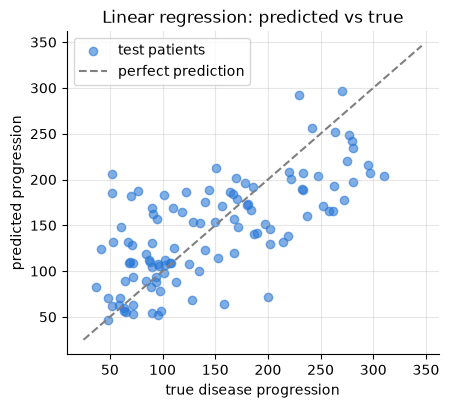

In [23]:
yd_hat = linreg.predict(Xd_test)
plt.figure(figsize=(4.8, 4.2))
plt.scatter(yd_test, yd_hat, alpha=0.6, color=BLUE, label="test patients")
lims = [yd.min(), yd.max()]
plt.plot(lims, lims, "--", color="gray", label="perfect prediction")   # the y = x line
plt.xlabel("true disease progression"); plt.ylabel("predicted progression")
plt.title("Linear regression: predicted vs true"); plt.legend(); plt.show()

**What just happened?** Points on the dashed line would be perfect predictions. The cloud follows the line's direction but is wide, matching an R² of about 0.5. Notice the model pulls extreme values toward the middle: very high true values tend to be under-predicted, and very low ones over-predicted.

---
## 14. The ML checklist (reuse it on every project)

| # | Step | Question to ask yourself |
|---|---|---|
| 1 | **Question** | What exactly am I predicting, for whom, and which mistake is more costly? Classification or regression? |
| 2 | **Look at the data** | Shape, column types, missing values, class balance, one or two plots. Anything suspicious? |
| 3 | **X and y** | Is the target (or anything computed from it, or only known *after* the fact) out of `X`? |
| 4 | **Split first** | Test set held out *before* any preprocessing? `stratify` for classification? Time order respected for time data? |
| 5 | **Baseline** | What does `DummyClassifier` / `DummyRegressor` score? |
| 6 | **Pipeline** | Are *all* preprocessing steps inside a `Pipeline`, fitted on training data only? |
| 7 | **Metric** | Which metric matches the real cost of mistakes (recall? precision? MAE?), not just accuracy? |
| 8 | **Cross-validate and tune** | Model choices and hyperparameters picked with CV on the **training set** only? |
| 9 | **Final test once** | Test set used exactly once? Is the result close to the CV estimate? |
| 10 | **Save and serve** | Whole pipeline saved, library versions noted, input columns checked on new data? |

---
## Recap

- An ML project starts with a **question**; here, *malignant or benign?* (classification) and *how much progression?* (regression).
- **`X`** = features, **`y`** = target. Recode so that `1` is the class you want to detect.
- **Split before anything else**; `stratify=y` keeps class ratios; the **test set is used once**.
- A **baseline** (here about 63% accuracy, and 0 cancers caught) tells you what "learning nothing" looks like.
- A **Pipeline** (`StandardScaler` + `LogisticRegression`) bundles preprocessing and model; `fit` learns, `predict` answers, `predict_proba` gives probabilities.
- The **confusion matrix** shows the kinds of mistakes; **precision** = how trustworthy an alarm is, **recall** = how many real cases are caught, **F1** combines them; **accuracy can lie** on imbalanced data.
- **Overfitting** = big gap between training and validation scores; **underfitting** = both low.
- **Cross-validation** gives a stable estimate; **GridSearchCV** tunes hyperparameters on the training set only.
- **Leakage** (e.g. selecting features on all data) can make pure noise look predictive; keep every step in a pipeline.
- **joblib** saves the whole pipeline; new data must have exactly the training columns.
- For regression: **MAE** (average miss), **RMSE** (punishes big misses), **R²** (fraction of variation explained), always compared with a mean baseline.

## Exercises

**1. (easy) A different baseline.** Replace `strategy="most_frequent"` with `strategy="stratified"` (random guesses in the class proportions) in Section 5. What accuracy and recall do you get on the test set? Why is it worse than "most frequent" on accuracy but not on recall?

<details><summary>Show solution</summary>

```python
b2 = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, y_train)
p2 = b2.predict(X_test)
print(metrics.accuracy_score(y_test, p2), metrics.recall_score(y_test, p2))
```
It guesses "malignant" about 37% of the time at random, so it catches some cancers by luck (recall about 0.40 with this seed) but makes many random errors (accuracy about 0.57). Still a useless model: it just spreads its mistakes differently.
</details>

**2. (easy) Another model, same pipeline.** Swap `LogisticRegression` for `DecisionTreeClassifier(max_depth=4, random_state=SEED)` inside the pipeline and compute the 5-fold CV accuracy on the training set. Which is better here?

<details><summary>Show solution</summary>

```python
tree_pipe = Pipeline([("scale", StandardScaler()),
                      ("model", DecisionTreeClassifier(max_depth=4, random_state=SEED))])
print(cross_val_score(tree_pipe, X_train, y_train, cv=cv).mean())
```
The tree scores lower than logistic regression on this dataset (about 0.93 vs about 0.97 CV accuracy). Trees don't need scaling, but leaving the scaler in does no harm.
</details>

**3. (medium) Tune the tree.** Use `GridSearchCV` to choose `max_depth` from `[1, 2, 3, 4, 5, 6, 8, None]` for a plain `DecisionTreeClassifier(random_state=SEED)` with `scoring="recall"`. Which depth wins? Evaluate it once on the test set.

<details><summary>Show solution</summary>

```python
g = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                 {"max_depth": [1, 2, 3, 4, 5, 6, 8, None]}, cv=cv, scoring="recall")
g.fit(X_train, y_train)
print(g.best_params_, round(g.best_score_, 3))
print("test recall:", metrics.recall_score(y_test, g.predict(X_test)))
```
With these folds `max_depth=5` wins (mean CV recall about 0.91) and its test recall is about 0.87, clearly below logistic regression's 0.925. The winning depth depends on the folds; what matters is that the choice was made on the training set only.
</details>

**4. (medium) Leakage with fewer features.** In Section 11 change `k=20` to `k=5`, then to `k=100`. How does the leaky score change? Does the correct score change?

<details><summary>Show solution</summary>

```python
for k in [5, 20, 100]:
    rows = [leakage_experiment(seed, k=k) for seed in range(5)]
    print(k, pd.DataFrame(rows, columns=["leaky", "correct"]).mean().round(3).to_dict())
```
The leaky score **grows with `k`** (roughly 0.70 with `k=5` and above 0.9 with `k=100`): more hand-picked noise features give the model more chance patterns to exploit. The correct score stays around 0.5 for every `k` (wobbling a few points, since 200 rows is a small sample). No amount of tuning makes noise predictive, unless you leak.
</details>

**5. (harder) Regression with a pipeline and cross-validation.** For the diabetes data, compare `LinearRegression` with `Pipeline([("scale", StandardScaler()), ("model", Ridge())])` (import `Ridge` from `sklearn.linear_model`), tuning `model__alpha` over `[0.01, 0.1, 1, 10, 100]` with `GridSearchCV(..., scoring="neg_root_mean_squared_error")` on the training set. Why is the score negative? Report the test RMSE of the winner.

<details><summary>Show solution</summary>

```python
from sklearn.linear_model import Ridge
ridge_pipe = Pipeline([("scale", StandardScaler()), ("model", Ridge())])
g = GridSearchCV(ridge_pipe, {"model__alpha": [0.01, 0.1, 1, 10, 100]},
                 cv=5, scoring="neg_root_mean_squared_error").fit(Xd_train, yd_train)
print(g.best_params_, -g.best_score_)            # flip the sign back to get RMSE
lin_cv = -cross_val_score(LinearRegression(), Xd_train, yd_train, cv=5,
                          scoring="neg_root_mean_squared_error").mean()
print("LinearRegression CV RMSE:", lin_cv)
print("Ridge test RMSE:", metrics.root_mean_squared_error(yd_test, g.predict(Xd_test)))
```
scikit-learn always **maximises** scores, so error metrics are reported as negative numbers ("bigger is better" then means "smaller error"). Here the best `alpha` is 1 and Ridge's CV RMSE (about 56.0) is practically identical to plain linear regression's; the winner's test RMSE is about 53.3. On a small dataset with only 10 features, regularisation has little to fix.
</details>

## Where to go next

- **Next folder:** [`01_supervised/`](01_supervised/), starting with [`00_preprocessing.ipynb`](01_supervised/00_preprocessing.ipynb), then [`01_linear_regression.ipynb`](01_supervised/01_linear_regression.ipynb) and [`02_logistic_regression.ipynb`](01_supervised/02_logistic_regression.ipynb) to see what happens *inside* the two models used here. The written guide is [`01_supervised/notes/01_supervised.md`](01_supervised/notes/01_supervised.md).
- **Pipelines and leakage in depth:** [`01_supervised/09_pipeline_and_leakage.ipynb`](01_supervised/09_pipeline_and_leakage.ipynb), then a full project in [`01_supervised/10_end_to_end_project.ipynb`](01_supervised/10_end_to_end_project.ipynb).
- **A realistic business project with the same checklist:** [`01_supervised/14_industry_churn_prediction.ipynb`](01_supervised/14_industry_churn_prediction.ipynb) (predicting which customers will leave).
- **More on evaluation:** [`06_model_evaluation/01_model_evaluation.ipynb`](06_model_evaluation/01_model_evaluation.ipynb), [`06_model_evaluation/02_hyperparameter_optimization.ipynb`](06_model_evaluation/02_hyperparameter_optimization.ipynb) and [`10_evaluation_metrics_comprehensive.ipynb`](10_evaluation_metrics_comprehensive.ipynb).
- **Imbalanced data:** [`05_feature_engineering/02_imbalanced_data.ipynb`](05_feature_engineering/02_imbalanced_data.ipynb).
- **The math behind it, gently:** [`../14_Mathematics/00_start_here_math_notation_bridge.ipynb`](../14_Mathematics/00_start_here_math_notation_bridge.ipynb).
- **Overview of this whole folder:** [`notes/03_Machine_Learning.md`](notes/03_Machine_Learning.md).